# Performance benchmarks · short and overnight runs, 2026-10-25

Visual summary of the benchmark runs in `spec/2026-10-23-dino-detr-head-port/`:

- **Short runs S1–S3** (`bench-short-runs.md`): crash checks.
- **Overnight jobs A–D** (`bench-overnight-runs.md`): the real measurements.

All runs used an NVIDIA L4 (ctcomp3, the project's worst-case GPU) with the native policy (448×560 input, 32×40 tokens).
Three optimisations are measured:

1. **Fused SDPA attention** in the frozen DINOv2 encoder, in place of the pinned hub code's unfused fallback (jobs A/B).
2. **FLIR staged on node-local scratch** instead of read from BeeGFS (A vs B).
3. **detrex's compiled CUDA MSDA** in the DINO head, instead of its pure-PyTorch fallback (C vs D).

**Headline:**
- **SDPA makes the encoder 2.4× faster** (37 → 90 frames/s in fp16) **and uses 65 % less memory.** Its drift is smaller than that of the fp16 inference the project already uses.
- **Compiled MSDA makes the head 1.9× faster in training and 2.6× faster in inference.**
- **Together, detector inference drops from 80 to 31 ms per frame (2.55×).**
- **Staging the data does not change end-to-end speed:** even at 89 frames/s the GPU, not data loading, stays the limit.

The notebook only **reads** `throughput.json` / `head_bench.json` from the pinned run dirs below.
Setup: `uv sync --group notebook`.

In [1]:
import json
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# Run dirs copied from the cluster into <repo>/outputs/; falls back to $IRWM_OUTPUT_ROOT.
OUT = Path("../outputs")
if not OUT.is_dir():
    from irwm.utils.paths import load_env, output_root

    load_env()
    OUT = output_root()

# key: (run dir, results file, kind, what it measures)
RUNS = {
    "S2": ("feature_extraction/2026-10-25/13-09-29", "throughput.json", "short", "encoder, crash check"),
    "S2 (old)": ("feature_extraction/2026-10-25/12-49-45", "throughput.json", "short", "encoder, old stretch defaults (code path only)"),
    "S3": ("detection/2026-10-25/13-15-30", "head_bench.json", "short", "head, PyTorch MSDA, crash check"),
    "A": ("feature_extraction/2026-10-25/13-28-51", "throughput.json", "overnight", "encoder, data on BeeGFS"),
    "B": ("feature_extraction/2026-10-25/13-34-14", "throughput.json", "overnight", "encoder, data staged to local scratch"),
    "C": ("detection/2026-10-25/13-30-17", "head_bench.json", "overnight", "head, compiled CUDA MSDA"),
    "D": ("detection/2026-10-25/13-30-40", "head_bench.json", "overnight", "head, PyTorch MSDA"),
}
R = {k: json.loads((OUT / d / f).read_text()) for k, (d, f, *_) in RUNS.items()}
A, B, C, D = R["A"], R["B"], R["C"], R["D"]
assert not A["staged"] and B["staged"] and C["msda"] == "cuda" and D["msda"] == "pytorch"
assert all(R[k]["gpu"] == "NVIDIA L4" for k in RUNS)


def started(key):
    """Python start time, from the Hydra run dir name."""
    return datetime.strptime(RUNS[key][0][-19:], "%Y-%m-%d/%H-%M-%S")


def wandb_run(key):
    """(run id, start time) of the run's W&B run; W&B is initialised only after the benchmark, so this is about its end."""
    runs = sorted((OUT / RUNS[key][0] / "wandb").glob("run-*"))
    if not runs:
        return "–", "–"
    _, stamp, run_id = runs[-1].name.split("-")
    return run_id, f"{stamp[9:11]}:{stamp[11:13]}:{stamp[13:15]}"


for k in RUNS:
    print(f"{k:9s} {RUNS[k][0]}  commit {R[k]['git']['commit'][:7]} dirty={R[k]['git']['dirty']}  torch {R[k]['torch']}")

S2        feature_extraction/2026-10-25/13-09-29  commit 9b5a7ff dirty=True  torch 2.2.0+cu121
S2 (old)  feature_extraction/2026-10-25/12-49-45  commit 51447d0 dirty=True  torch 2.2.0+cu121
S3        detection/2026-10-25/13-15-30  commit 9b5a7ff dirty=True  torch 2.2.0+cu121
A         feature_extraction/2026-10-25/13-28-51  commit 9b5a7ff dirty=True  torch 2.2.0+cu121
B         feature_extraction/2026-10-25/13-34-14  commit 9b5a7ff dirty=True  torch 2.2.0+cu121
C         detection/2026-10-25/13-30-17  commit 9b5a7ff dirty=True  torch 2.2.0+cu121
D         detection/2026-10-25/13-30-40  commit 9b5a7ff dirty=True  torch 2.2.0+cu121


In [2]:
# Plot style, same as encoder_r5_results.ipynb.
# Categorical slots 1-2 encode the *unoptimised* (blue) and *optimised* (orange) variant of every comparison;
# slots 3-4 the two components of the detector. Precision is line style (fp16 solid, fp32 dashed).
BASE, OPT = "#2a78d6", "#eb6834"
ATTS = ["plain", "sdpa"]
ATT_COLOR = {"plain": BASE, "sdpa": OPT}
ATT_LABEL = {"plain": "plain (unfused)", "sdpa": "SDPA (fused)"}
MSDAS = ["pytorch", "cuda"]
MSDA_RUN = {"pytorch": "D", "cuda": "C"}
MSDA_COLOR = {"pytorch": BASE, "cuda": OPT}
MSDA_LABEL = {"pytorch": "PyTorch MSDA", "cuda": "compiled CUDA MSDA"}
STORE_COLOR = {"A": BASE, "B": OPT}
STORE_LABEL = {"A": "BeeGFS (A)", "B": "staged, page cache (B)"}
PART_COLOR = {"encoder": "#1baf7a", "head": "#eda100"}
PRECS = ["fp16", "fp32"]
PREC_LS = {"fp16": "-", "fp32": "--"}
MODS = ["rgb", "thermal"]
MOD_LABEL = {"rgb": "RGB", "thermal": "Thermal"}
REF_COLOR = "#a8a7a2"  # earlier reference measurements (F4), deliberately recessive
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def num(v):
    return np.nan if v == "oom" else v


# Lookups used throughout.
gA = {(r["attention"], r["precision"], r["batch_size"]): r for r in A["gpu_only"] if r["size"] == [448, 560]}
e2e = {(k, r["attention"], r["modality"]): r for k in ["A", "B"] for r in R[k]["end_to_end"]}
loader = {(k, r["modality"]): r for k in ["A", "B"] for r in R[k]["loader_only"]}
head = {(m, r["mode"], r["precision"], r["batch_size"]): r for m in MSDAS for r in R[MSDA_RUN[m]]["runs"]}


def hv(msda, mode, precision, batch, key):
    r = head[(msda, mode, precision, batch)]
    return np.nan if r["oom"] else r[key]

## 1. Did every run finish?

The expected row count of each section comes from the run's own config (e.g. GPU-only = attentions × sizes × precisions × batch sizes).
A section passes when it has every row and none ran out of memory. Job B skips GPU-only by design (`run_gpu_only=false`).

In [3]:
def expected(d):
    c = d["config"]
    if "runs" in d:
        return {"runs": len(c["modes"]) * len(c["grids"]) * len(c["batch_sizes"]) * len(c["precisions"])}
    gpu = len(c["attentions"]) * len(c["sizes"]) * len(c["precisions"]) * len(c["batch_sizes"])
    return {"gpu_only": gpu if c["run_gpu_only"] else 0, "fidelity": len(c["sizes"]) * len(c["precisions"]),
            "end_to_end": 2 * len(c["attentions"]), "loader_only": 2}  # 2 = rgb, thermal


def n_oom(rows):
    return sum(r.get("oom") is True or r.get("frames_per_s") == "oom" for r in rows)


rows = [["S1", "pytest `test_attention_sdpa.py` + `test_encoder.py`", "–", "–", "⏳ pending: summary line not pasted yet"]]
for k in RUNS:
    for section, n in expected(R[k]).items():
        got = R[k].get(section, [])
        ok = len(got) == n and n_oom(got) == 0
        rows.append([k, f"`{section}`", f"{len(got)}/{n}", n_oom(got), "✅ complete" if ok else "❌ check"])
table(["run", "section", "rows", "OOM", "status"], rows)

rows = []
for k, (d, _, kind, what) in RUNS.items():
    r = R[k]
    setup = (f"staged={r['staged']}, {r['slurm_cpus_per_task']} CPUs, {r['config']['num_workers']} workers" if "staged" in r
             else f"msda={r['msda']} (CUDA ops available: {r['cuda_ops_available']})")
    run_id, wb = wandb_run(k)
    rows.append([k, kind, what, r.get("host", "–"), setup, started(k).strftime("%H:%M:%S"), wb, f"`{run_id}`"])
table(["run", "kind", "measures", "host", "setup", "started", "W&B init (≈ end)", "W&B id"], rows)

| run | section | rows | OOM | status |
|---|---|---|---|---|
| S1 | pytest `test_attention_sdpa.py` + `test_encoder.py` | – | – | ⏳ pending: summary line not pasted yet |
| S2 | `gpu_only` | 4/4 | 0 | ✅ complete |
| S2 | `fidelity` | 2/2 | 0 | ✅ complete |
| S2 | `end_to_end` | 4/4 | 0 | ✅ complete |
| S2 | `loader_only` | 2/2 | 0 | ✅ complete |
| S2 (old) | `gpu_only` | 4/4 | 0 | ✅ complete |
| S2 (old) | `fidelity` | 2/2 | 0 | ✅ complete |
| S2 (old) | `end_to_end` | 4/4 | 0 | ✅ complete |
| S2 (old) | `loader_only` | 2/2 | 0 | ✅ complete |
| S3 | `runs` | 4/4 | 0 | ✅ complete |
| A | `gpu_only` | 16/16 | 0 | ✅ complete |
| A | `fidelity` | 2/2 | 0 | ✅ complete |
| A | `end_to_end` | 4/4 | 0 | ✅ complete |
| A | `loader_only` | 2/2 | 0 | ✅ complete |
| B | `gpu_only` | 0/0 | 0 | ✅ complete |
| B | `fidelity` | 2/2 | 0 | ✅ complete |
| B | `end_to_end` | 4/4 | 0 | ✅ complete |
| B | `loader_only` | 2/2 | 0 | ✅ complete |
| C | `runs` | 16/16 | 0 | ✅ complete |
| D | `runs` | 16/16 | 0 | ✅ complete |

| run | kind | measures | host | setup | started | W&B init (≈ end) | W&B id |
|---|---|---|---|---|---|---|---|
| S2 | short | encoder, crash check | hpc-gpu5 | staged=False, 4 CPUs, 4 workers | 13:09:29 | – | `–` |
| S2 (old) | short | encoder, old stretch defaults (code path only) | hpc-gpu5 | staged=False, 4 CPUs, 4 workers | 12:49:45 | – | `–` |
| S3 | short | head, PyTorch MSDA, crash check | – | msda=pytorch (CUDA ops available: True) | 13:15:30 | – | `–` |
| A | overnight | encoder, data on BeeGFS | hpc-gpu5 | staged=False, 8 CPUs, 8 workers | 13:28:51 | 13:42:03 | `6o47ocr3` |
| B | overnight | encoder, data staged to local scratch | hpc-gpu5 | staged=True, 8 CPUs, 8 workers | 13:34:14 | 13:39:24 | `xlop65eg` |
| C | overnight | head, compiled CUDA MSDA | – | msda=cuda (CUDA ops available: True) | 13:30:17 | 13:31:13 | `4c11kfnm` |
| D | overnight | head, PyTorch MSDA | – | msda=pytorch (CUDA ops available: True) | 13:30:40 | 13:32:13 | `64y1udph` |

- **All overnight jobs finished with every row and no OOM.** Nothing has to be rerun.
- All runs used commit `9b5a7ff` + uncommitted changes (`dirty=True`), i.e. the same code as the short runs.
- C/D ran with `cuda_ops_available` true, so D's PyTorch MSDA is the shim, not a fallback for a missing op.
- S2 ran with 4 CPUs and 4 workers; A/B ran with 8 CPUs and 8 workers, as planned.
- **Not in `outputs/`: the SLURM logs** (`irwm-*-552566{5..8}.out`). They hold B's `[stage] copied N files in T s` line and any SDPA backend fallback warning. The Hydra `.log` files and W&B `output.log` contain neither, because W&B starts only after the benchmark.

## 2. Accuracy cost of SDPA

`fidelity` = SDPA vs plain `encode_pca` (1152 PCA channels) on the same random batch `[4, 3, 448, 560]`, for each precision.
The grey bar is the reference the project already accepts: the plain encoder's own **fp16 vs fp32** drift from F4
(`spec/2026-10-16-dinov2-reg-encoder-wrapper/results.md §1`, Test C). If SDPA's fp16 bar is at or below it, the speed-up
costs no more accuracy than the fp16 that is already in use. Log scale; lower is better.

fidelity rows bit-identical in: S2, A, B (same seed, same kernels)


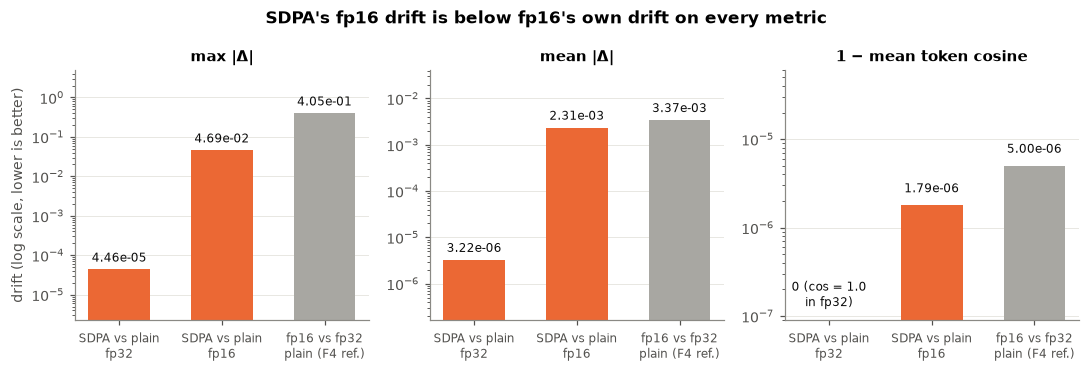

| metric | SDPA vs plain, fp32 | SDPA vs plain, fp16 | F4 fp16 vs fp32 (plain) | SDPA fp16 vs F4 ref. |
|---|---|---|---|---|
| max |Δ| | 4.46e-05 | 4.69e-02 | 4.05e-01 | 8.6× smaller |
| mean |Δ| | 3.22e-06 | 2.31e-03 | 3.37e-03 | 1.5× smaller |
| 1 − mean token cosine | 0.00e+00 | 1.79e-06 | 5.00e-06 | 2.8× smaller |
| min token cosine | 0.9999998 | 0.9999813 | – | – |
| mean token cosine | 1.0000000 | 0.9999982 | 0.999995 | ≥ 0.999 expected |

In [4]:
same = [k for k in ["S2", "A", "B"] if R[k]["fidelity"] == R["S2"]["fidelity"]]
print(f"fidelity rows bit-identical in: {', '.join(same)} (same seed, same kernels)")

F4_FP16_VS_FP32 = {"max_abs_diff": 4.05e-1, "mean_abs_diff": 3.37e-3, "mean_token_cosine": 0.999995}  # results.md §1, Test C
fid = {r["precision"]: r for r in A["fidelity"] if r["size"] == [448, 560]}
METRICS = [("max_abs_diff", "max |Δ|"), ("mean_abs_diff", "mean |Δ|"), ("one_minus_cos", "1 − mean token cosine")]
BARS = [("SDPA vs plain\nfp32", fid["fp32"], OPT),
        ("SDPA vs plain\nfp16", fid["fp16"], OPT),
        ("fp16 vs fp32\nplain (F4 ref.)", F4_FP16_VS_FP32, REF_COLOR)]


def metric(row, key):
    return 1 - row["mean_token_cosine"] if key == "one_minus_cos" else row[key]


fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (key, label) in zip(axes, METRICS):
    vals = [metric(row, key) for _, row, _ in BARS]
    floor = min(v for v in vals if v > 0) / 20
    xs = np.arange(len(BARS))
    ax.bar(xs, [max(v, floor) for v in vals], width=0.6, color=[c for *_, c in BARS])
    for x, v in zip(xs, vals):
        ax.text(x, max(v, floor) * 1.3, f"{v:.2e}" if v > 0 else "0 (cos = 1.0\nin fp32)",
                ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_yscale("log")
    ax.set_ylim(floor, max(vals) * 12)
    ax.set_xticks(xs, [b[0] for b in BARS], fontsize=8)
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("drift (log scale, lower is better)")
fig.suptitle("SDPA's fp16 drift is below fp16's own drift on every metric", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

rows = []
for key, label in METRICS:
    s32, s16, ref = (metric(fid["fp32"], key), metric(fid["fp16"], key), metric(F4_FP16_VS_FP32, key))
    rows.append([label, f"{s32:.2e}", f"{s16:.2e}", f"{ref:.2e}", f"{ref / s16:.1f}× smaller"])
rows.append(["min token cosine", f"{fid['fp32']['min_token_cosine']:.7f}", f"{fid['fp16']['min_token_cosine']:.7f}", "–", "–"])
rows.append(["mean token cosine", f"{fid['fp32']['mean_token_cosine']:.7f}", f"{fid['fp16']['mean_token_cosine']:.7f}",
             f"{F4_FP16_VS_FP32['mean_token_cosine']:.6f}", "≥ 0.999 expected"])
table(["metric", "SDPA vs plain, fp32", "SDPA vs plain, fp16", "F4 fp16 vs fp32 (plain)", "SDPA fp16 vs F4 ref."], rows)

- **fp32:** SDPA matches plain attention to about 3e-6 mean |Δ| (max 4.5e-5), and the token cosine rounds to 1.0. This is only a reordering of floating-point operations.
- **fp16:** SDPA's drift is smaller than fp16's own drift: about 9× on max |Δ|, 1.5× on mean |Δ| and 3× on 1 − cosine. Fused kernels accumulate the softmax in higher precision than the explicit `q @ kᵀ → softmax` in fp16, so this is expected.
- **The comparison is not like-for-like:** S2/A/B used **random-noise** input, 4 frames at 448×560. F4 used **5 real Cityscapes frames** at 448×896. Attention maps on noise are flatter than on real images. A check on real FLIR frames would settle this, if a reviewer asks for one.
- F4's max |Δ| was a single outlier coefficient. Mean |Δ| and cosine are the more robust comparison, and SDPA is below the reference on both.

## 3. Encoder: SDPA vs plain attention (job A, GPU-only)

Synthetic `[B, 3, 448, 560]` input, 5 warm-up + 20 timed batches per point, `encode_pca` (backbone + PCA).
Colour = attention, line style = precision.

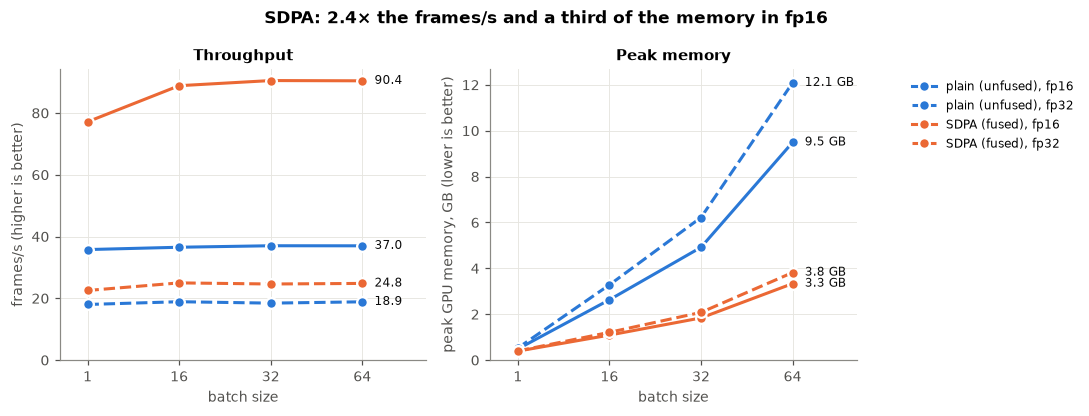

| precision | batch | plain fps | SDPA fps | speed-up | plain GB | SDPA GB | memory | F4 plain fps (A vs F4) |
|---|---|---|---|---|---|---|---|---|
| fp16 | 1 | 35.8 | 77.2 | **2.16×** | 0.49 | 0.39 | -19 % | 33.4 (+7.2 %) |
| fp16 | 16 | 36.6 | 88.8 | **2.43×** | 2.63 | 1.09 | -59 % | 36.0 (+1.5 %) |
| fp16 | 32 | 37.0 | 90.5 | **2.44×** | 4.92 | 1.84 | -63 % | – |
| fp16 | 64 | 37.0 | 90.4 | **2.44×** | 9.49 | 3.34 | -65 % | 36.8 (+0.6 %) |
| fp32 | 1 | 18.0 | 22.6 | **1.25×** | 0.53 | 0.40 | -24 % | 17.8 (+1.3 %) |
| fp32 | 16 | 18.9 | 25.0 | **1.32×** | 3.28 | 1.21 | -63 % | 18.9 (+0.1 %) |
| fp32 | 32 | 18.5 | 24.6 | **1.34×** | 6.22 | 2.08 | -67 % | – |
| fp32 | 64 | 18.9 | 24.8 | **1.32×** | 12.09 | 3.82 | -68 % | 18.9 (-0.1 %) |

In [5]:
BS = sorted({b for (_, _, b) in gA})
xs = np.arange(len(BS))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, key, ylabel, fmt in [(axes[0], "frames_per_s", "frames/s (higher is better)", "{:.1f}"),
                             (axes[1], "peak_mem_gb", "peak GPU memory, GB (lower is better)", "{:.1f} GB")]:
    for a in ATTS:
        for p in PRECS:
            ys = [num(gA[(a, p, b)][key]) for b in BS]
            ax.plot(xs, ys, color=ATT_COLOR[a], ls=PREC_LS[p], lw=2, marker="o", ms=7, mec="white", mew=1.5,
                    label=f"{ATT_LABEL[a]}, {p}")
            ax.annotate(fmt.format(ys[-1]), (xs[-1], ys[-1]), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK)
    ax.set_xticks(xs, BS)
    ax.set_xlim(-0.3, len(BS) - 0.3)
    ax.set_ylim(0, None)
    ax.set_xlabel("batch size")
    ax.set_ylabel(ylabel)
axes[0].set_title("Throughput")
axes[1].set_title("Peak memory")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.12, 1), fontsize=8)
fig.suptitle("SDPA: 2.4× the frames/s and a third of the memory in fp16", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

F4_PLAIN = {("fp16", 1): 33.4, ("fp16", 16): 36.0, ("fp16", 64): 36.8,
            ("fp32", 1): 17.8, ("fp32", 16): 18.9, ("fp32", 64): 18.9}  # results.md §3, 448x560, frames/s
rows = []
for p in PRECS:
    for b in BS:
        pl, sd = gA[("plain", p, b)], gA[("sdpa", p, b)]
        f4 = F4_PLAIN.get((p, b))
        rows.append([p, b, f"{pl['frames_per_s']:.1f}", f"{sd['frames_per_s']:.1f}",
                     f"**{sd['frames_per_s'] / pl['frames_per_s']:.2f}×**",
                     f"{pl['peak_mem_gb']:.2f}", f"{sd['peak_mem_gb']:.2f}", f"{100 * (sd['peak_mem_gb'] / pl['peak_mem_gb'] - 1):+.0f} %",
                     "–" if f4 is None else f"{f4:.1f} ({100 * (pl['frames_per_s'] / f4 - 1):+.1f} %)"])
table(["precision", "batch", "plain fps", "SDPA fps", "speed-up", "plain GB", "SDPA GB", "memory", "F4 plain fps (A vs F4)"], rows)

- **A's plain rows reproduce F4** within 1.5 % from batch 16 up (memory too: 9.5 / 12.1 GB at B = 64). Nothing else in the encoder changed.
- **fp16: 2.4× faster from batch 16 up** (37.0 → 90.5 fps), 2.2× at batch 1. FlashAttention-2 runs only in fp16/bf16, so this is where SDPA helps most.
- **fp32: only 1.3×.** In fp32, SDPA uses the memory-efficient backend instead. fp16 stays the default.
- **Memory: −59 % to −68 % from batch 16 up.** The plain path materialises the full `[B, heads, tokens, tokens]` score matrix; SDPA never does.
  - The largest batch tested (64) fits for both attentions in both precisions, so **B = 64 fp32 fits** (12.1 GB plain, 3.8 GB SDPA).
  - With SDPA, about 6× larger batches would fit in the L4's 24 GB.
- Speed is flat from batch 16: the L4 is compute-bound there, so larger batches only cost memory.
- A's batch-1 SDPA fp16 row (77.2 fps) is 6 % below S2's (82.5). Batch 1 is launch-bound and sensitive to CPU load, and A's GPU-only section overlapped B's staging copy on the same node.

## 4. Data loading: is it the bottleneck, and does staging help? (A vs B)

- **End-to-end** = FLIR train → `Preprocess("native")` in 8 DataLoader workers → fp16 `encode_pca`, batch 32, 10 warm-up + 100 timed batches.
- **Loader-only** = the same DataLoader with no GPU work (10 warm-up + 60 timed batches): the read + decode + resize rate of the data source.

In the chart, the bars are the loader's capacity and the dashed lines are what the encoder consumes (GPU-only, B = 32, fp16).
A bar far above a line means data loading has headroom over that encoder.

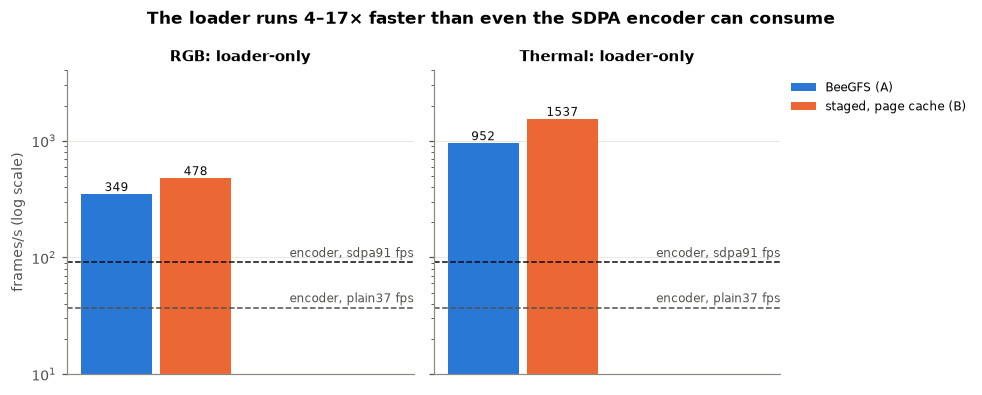

**Loader-only** (frames 7040–9279 of the train split)

| modality | BeeGFS fps (A) | staged fps (B) | B ÷ A | headroom over SDPA e2e (A) | headroom (B) |
|---|---|---|---|---|---|
| RGB | 349 | 478 | 1.37× | 3.9× | 5.3× |
| Thermal | 952 | 1537 | 1.61× | 10.7× | 17.3× |

**End-to-end** (3,200 timed frames per row; plain frames 0–3519, SDPA frames 3520–7039)

| modality | attention | BeeGFS fps (A) | staged fps (B) | B ÷ A | encode share A / B | GPU-only fps (B = 32, fp16) | A e2e ÷ GPU-only |
|---|---|---|---|---|---|---|---|
| RGB | plain | 36.7 | 37.3 | 1.016× | 0.9995 / 0.9993 | 37.0 | 99.1 % |
| RGB | sdpa | 89.3 | 89.3 | 0.999× | 0.9987 / 0.9988 | 90.5 | 98.7 % |
| Thermal | plain | 36.7 | 36.5 | 0.994× | 0.9995 / 0.9994 | 37.0 | 99.0 % |
| Thermal | sdpa | 89.0 | 88.8 | 0.998× | 0.9988 / 0.9986 | 90.5 | 98.3 % |

In [7]:
gpu32 = {a: gA[(a, "fp16", 32)]["frames_per_s"] for a in ATTS}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
w = 0.36
for ax, m in zip(axes, MODS):
    for i, k in enumerate(["A", "B"]):
        v = loader[(k, m)]["frames_per_s"]
        x = (i - 0.5) * (w + 0.04)
        ax.bar(x, v, width=w, color=STORE_COLOR[k], label=STORE_LABEL[k])
        ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=INK)
    for a in ATTS:
        ax.axhline(gpu32[a], color=INK if a == "sdpa" else MUTED, ls="--", lw=1)
        ax.text(1.3, gpu32[a] * 1.05, f"encoder, {a}{gpu32[a]:.0f} fps", va="bottom", ha="right", fontsize=8, color=MUTED)
    ax.set_xticks([])
    ax.set_xlim(-0.45, 1.3)
    ax.set_yscale("log")
    ax.set_ylim(10, 4000)
    ax.set_title(f"{MOD_LABEL[m]}: loader-only")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("frames/s (log scale)")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
fig.suptitle("The loader runs 4–17× faster than even the SDPA encoder can consume", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

rows = []
for m in MODS:
    a, b = loader[("A", m)]["frames_per_s"], loader[("B", m)]["frames_per_s"]
    sd = e2e[("A", "sdpa", m)]["frames_per_s"]
    rows.append([MOD_LABEL[m], f"{a:.0f}", f"{b:.0f}", f"{b / a:.2f}×", f"{a / sd:.1f}×", f"{b / sd:.1f}×"])
display(Markdown("**Loader-only** (frames 7040–9279 of the train split)"))
table(["modality", "BeeGFS fps (A)", "staged fps (B)", "B ÷ A", "headroom over SDPA e2e (A)", "headroom (B)"], rows)

rows = []
for m in MODS:
    for att in ATTS:
        ra, rb = e2e[("A", att, m)], e2e[("B", att, m)]
        rows.append([MOD_LABEL[m], att, f"{ra['frames_per_s']:.1f}", f"{rb['frames_per_s']:.1f}",
                     f"{rb['frames_per_s'] / ra['frames_per_s']:.3f}×", f"{ra['encode_share']:.4f} / {rb['encode_share']:.4f}",
                     f"{gpu32[att]:.1f}", f"{100 * ra['frames_per_s'] / gpu32[att]:.1f} %"])
display(Markdown("**End-to-end** (3,200 timed frames per row; plain frames 0–3519, SDPA frames 3520–7039)"))
table(["modality", "attention", "BeeGFS fps (A)", "staged fps (B)", "B ÷ A", "encode share A / B",
       "GPU-only fps (B = 32, fp16)", "A e2e ÷ GPU-only"], rows)

- **SDPA does not move the bottleneck.** End to end runs at 99 % of the GPU-only rate, with an encode share of 0.999 on both data sources. The GPU is still the limit at 89 fps.
- **Staging speeds up the loader itself** (RGB 1.4×, thermal 1.6×) **but not the pipeline:** end-to-end B ÷ A is within ±1.6 %, which is noise.
- 8 workers reading from BeeGFS already deliver 349 RGB / 952 thermal fps, 3.9× / 10.7× what the SDPA encoder consumes. Fewer workers, or a faster GPU (about 4× an L4 for RGB), would be needed before BeeGFS became the limit.
- Thermal decodes much faster than RGB: 640×512 single-channel images vs larger RGB JPEGs.

In [8]:
# What staging costs vs what it saves, per job.
STAGE_COPY_S = 276.0  # R11: full copy, 12 GB at 44 MB/s. Replace with B's "[stage] copied N files in T s" (SLURM log 5525666).
LOAD_S = {"BeeGFS": 176.0, "scratch": 5.7}  # R11: FlirSplit.load, 6 annotation files (~260 MB)

rows = []
for m in MODS:
    pa, pb = e2e[("A", "sdpa", m)]["projected_epoch_s"], e2e[("B", "sdpa", m)]["projected_epoch_s"]
    rows.append([MOD_LABEL[m], e2e[("A", "sdpa", m)]["split_frames"], f"{pa:.1f}", f"{pb:.1f}", f"{pa - pb:+.1f}"])
table(["modality", "train frames", "epoch s, BeeGFS (A)", "epoch s, staged (B)", "saved per epoch, s"], rows)
saved = LOAD_S["BeeGFS"] - LOAD_S["scratch"]
display(Markdown(f"Per job: staging copy **{STAGE_COPY_S:.0f} s** vs annotation load saved **{saved:.0f} s** "
                 f"(R11) → net **{saved - STAGE_COPY_S:+.0f} s**, and no saving per epoch."))

# Did B's staging copy (network) overlap A's BeeGFS reads? A's GPU-only section runs first, on synthetic data.
gpu_only_s = sum(25 * r["batch_size"] / r["frames_per_s"] for r in A["gpu_only"])  # 5 warm-up + 20 timed each
a_reads = started("A") + timedelta(seconds=gpu_only_s)
display(Markdown(
    f"Overlap check: A started at {started('A'):%H:%M:%S}. Its GPU-only section alone is ≥ {gpu_only_s:.0f} s of encoding "
    f"(not counting model load and `FlirSplit.load`), so its first FLIR read was **after {a_reads:%H:%M:%S}**. "
    f"B's Python, which runs after the copy, started at **{started('B'):%H:%M:%S}**. A's BeeGFS reads therefore did not overlap "
    f"B's copy, but A's and B's end-to-end sections did run at the same time, from different data sources."))

| modality | train frames | epoch s, BeeGFS (A) | epoch s, staged (B) | saved per epoch, s |
|---|---|---|---|---|
| RGB | 10318 | 115.5 | 115.6 | -0.1 |
| Thermal | 10742 | 120.7 | 120.9 | -0.2 |

Per job: staging copy **276 s** vs annotation load saved **170 s** (R11) → net **-106 s**, and no saving per epoch.

Overlap check: A started at 13:28:51. Its GPU-only section alone is ≥ 372 s of encoding (not counting model load and `FlirSplit.load`), so its first FLIR read was **after 13:35:03**. B's Python, which runs after the copy, started at **13:34:14**. A's BeeGFS reads therefore did not overlap B's copy, but A's and B's end-to-end sections did run at the same time, from different data sources.

**Staging does not pay off for the encoder on an L4.** Its only real gain is the faster annotation load at job start (R11), which is smaller than the copy itself.
- It would matter on a faster GPU, or for a job that rereads the data over many epochs while the GPU waits.
- The copy time comes from R11; B's own `[stage] copied` line is in its SLURM log, which is not in `outputs/`. Paste it into `STAGE_COPY_S`.

## 5. DINO head: compiled CUDA MSDA vs PyTorch MSDA (C vs D)

Synthetic features `[B, 1152, 32, 40]`, 5 random boxes per image, 3 warm-up + 10 timed steps, median.
- **Train step:** forward, backward, grad clip, AdamW.
- **Infer step:** eval-mode forward under `no_grad`.

Colour = MSDA implementation, line style = precision (fp16 = autocast).

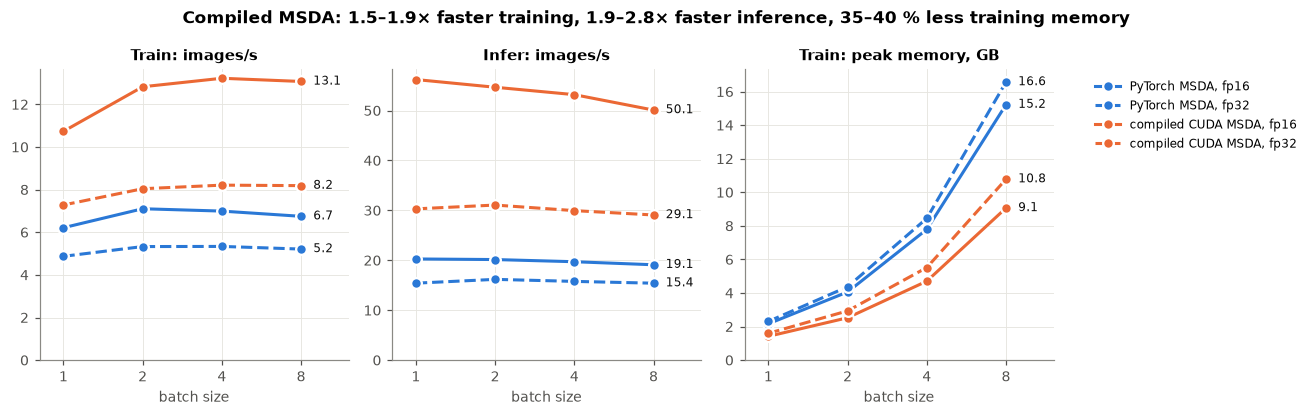

| mode | precision | batch | PyTorch ms/img | CUDA ms/img | PyTorch img/s | CUDA img/s | speed-up | PyTorch GB | CUDA GB | memory ratio |
|---|---|---|---|---|---|---|---|---|---|---|
| train | fp16 | 1 | 161 | 93 | 6.2 | 10.7 | **1.73×** | 2.17 | 1.42 | 0.66 |
| train | fp16 | 2 | 141 | 78 | 7.1 | 12.8 | **1.81×** | 4.06 | 2.53 | 0.62 |
| train | fp16 | 4 | 143 | 76 | 7.0 | 13.2 | **1.89×** | 7.79 | 4.71 | 0.60 |
| train | fp16 | 8 | 148 | 76 | 6.7 | 13.1 | **1.94×** | 15.22 | 9.07 | 0.60 |
| train | fp32 | 1 | 205 | 137 | 4.9 | 7.3 | **1.49×** | 2.31 | 1.60 | 0.69 |
| train | fp32 | 2 | 188 | 124 | 5.3 | 8.0 | **1.51×** | 4.37 | 2.93 | 0.67 |
| train | fp32 | 4 | 187 | 122 | 5.3 | 8.2 | **1.54×** | 8.45 | 5.52 | 0.65 |
| train | fp32 | 8 | 192 | 122 | 5.2 | 8.2 | **1.57×** | 16.57 | 10.78 | 0.65 |
| infer | fp16 | 1 | 49 | 18 | 20.3 | 56.2 | **2.77×** | 0.70 | 0.43 | 0.62 |
| infer | fp16 | 2 | 50 | 18 | 20.2 | 54.7 | **2.71×** | 1.11 | 0.53 | 0.48 |
| infer | fp16 | 4 | 51 | 19 | 19.7 | 53.2 | **2.70×** | 1.91 | 0.74 | 0.39 |
| infer | fp16 | 8 | 52 | 20 | 19.1 | 50.1 | **2.62×** | 3.52 | 1.17 | 0.33 |
| infer | fp32 | 1 | 65 | 33 | 15.4 | 30.3 | **1.97×** | 0.68 | 0.43 | 0.64 |
| infer | fp32 | 2 | 62 | 32 | 16.2 | 31.1 | **1.92×** | 1.08 | 0.52 | 0.48 |
| infer | fp32 | 4 | 63 | 33 | 15.8 | 30.0 | **1.90×** | 1.89 | 0.76 | 0.40 |
| infer | fp32 | 8 | 65 | 34 | 15.4 | 29.1 | **1.89×** | 3.50 | 1.26 | 0.36 |

In [9]:
BS_H = sorted({b for (_, _, _, b) in head})
xs = np.arange(len(BS_H))
panels = [("train", "images_per_s", "Train: images/s"), ("infer", "images_per_s", "Infer: images/s"),
          ("train", "peak_mem_gb", "Train: peak memory, GB")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (mode, key, title) in zip(axes, panels):
    for msda in MSDAS:
        for p in PRECS:
            ys = [hv(msda, mode, p, b, key) for b in BS_H]
            ax.plot(xs, ys, color=MSDA_COLOR[msda], ls=PREC_LS[p], lw=2, marker="o", ms=7, mec="white", mew=1.5,
                    label=f"{MSDA_LABEL[msda]}, {p}")
            ax.annotate(f"{ys[-1]:.1f}", (xs[-1], ys[-1]), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK)
    ax.set_xticks(xs, BS_H)
    ax.set_xlim(-0.3, len(BS_H) - 0.4)
    ax.set_ylim(0, None)
    ax.set_xlabel("batch size")
    ax.set_title(title)
axes[2].legend(loc="upper left", bbox_to_anchor=(1.1, 1), fontsize=8)
fig.suptitle("Compiled MSDA: 1.5–1.9× faster training, 1.9–2.8× faster inference, 35–40 % less training memory",
             fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

rows = []
for mode in ["train", "infer"]:
    for p in PRECS:
        for b in BS_H:
            pt, cu = (hv(m, mode, p, b, "images_per_s") for m in MSDAS)
            gpt, gcu = (hv(m, mode, p, b, "peak_mem_gb") for m in MSDAS)
            rows.append([mode, p, b, f"{1000 / pt:.0f}", f"{1000 / cu:.0f}", f"{pt:.1f}", f"{cu:.1f}", f"**{cu / pt:.2f}×**",
                         f"{gpt:.2f}", f"{gcu:.2f}", f"{gcu / gpt:.2f}"])
table(["mode", "precision", "batch", "PyTorch ms/img", "CUDA ms/img", "PyTorch img/s", "CUDA img/s", "speed-up",
       "PyTorch GB", "CUDA GB", "memory ratio"], rows)

- **Training:** compiled MSDA is 1.5–1.6× faster in fp32 and 1.7–1.9× in fp16, and uses 0.60–0.65× the memory at batch 8 (9.1 vs 15.2 GB in fp16).
- **Inference:** it is 1.9× faster in fp32 and **2.6–2.8× in fp16**. At batch 8 fp16 that is 20 ms vs 52 ms per image, at a third of the memory.
- **fp16 helps the PyTorch fallback little** (train 1.3×, infer 1.25×): detrex casts `value` to fp32 before the op, and the fallback's `grid_sample` runs in fp32 under autocast. The compiled op gains 1.6–1.7× from fp16.
- **D did not run out of memory** at any tested batch (max 16.6 GB, train B = 8 fp32), but it is the closer of the two to the L4's 24 GB.
- Throughput is flat beyond batch 2, so batching does not hide the fallback's cost.
- **The F7 overfit test's 0.7 s/step** (32×64, fp32, B = 4, compiled) is consistent with C's 0.49 s at 32×40: about 1.6× the tokens.

## 6. Inference cost of the whole detector

Time per frame = 1 / encoder fps + 1 / head infer fps.
- **Encoder:** the measured **end-to-end** rate (real FLIR, data loading included, batch 32, fp16).
- **Head:** infer at batch 8, fp16.

The two configurations:
- **Unoptimised:** plain attention + PyTorch MSDA + BeeGFS (A + D).
- **Optimised:** SDPA + compiled MSDA + staged data (B + C).

Chart: thermal.

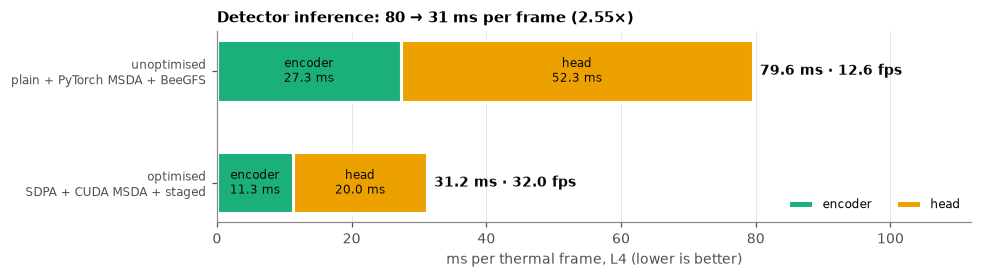

| modality | config | encoder ms | head ms | head share | total ms | frames/s | speed-up |
|---|---|---|---|---|---|---|---|
| RGB | unoptimised | 27.2 | 52.3 | 66 % | 79.6 | 12.6 | 1.00× |
| RGB | optimised | 11.2 | 20.0 | 64 % | 31.2 | 32.1 | 2.55× |
| Thermal | unoptimised | 27.3 | 52.3 | 66 % | 79.6 | 12.6 | 1.00× |
| Thermal | optimised | 11.3 | 20.0 | 64 % | 31.2 | 32.0 | 2.55× |

In [10]:
HEAD_B = 8
CONFIGS = {"unoptimised": ("A", "plain", "pytorch"), "optimised": ("B", "sdpa", "cuda")}
CONFIG_LABEL = {"unoptimised": "unoptimised\nplain + PyTorch MSDA + BeeGFS",
                "optimised": "optimised\nSDPA + CUDA MSDA + staged"}


def cost_ms(cfg, m):
    run, att, msda = CONFIGS[cfg]
    return {"encoder": 1000 / e2e[(run, att, m)]["frames_per_s"],
            "head": 1000 / hv(msda, "infer", "fp16", HEAD_B, "images_per_s")}


fig, ax = plt.subplots(figsize=(9, 2.6))
ys = np.arange(len(CONFIGS))[::-1]
for y, cfg in zip(ys, CONFIGS):
    c = cost_ms(cfg, "thermal")
    left = 0
    for part in ["encoder", "head"]:
        ax.barh(y, c[part], left=left, height=0.55, color=PART_COLOR[part], edgecolor="white", linewidth=2,
                label=part if cfg == "unoptimised" else None)
        ax.text(left + c[part] / 2, y, f"{part}\n{c[part]:.1f} ms", ha="center", va="center", fontsize=8, color=INK)
        left += c[part]
    ax.text(left + 1, y, f"{left:.1f} ms · {1000 / left:.1f} fps", va="center", fontsize=9, fontweight="bold", color=INK)
ax.set_yticks(ys, [CONFIG_LABEL[c] for c in CONFIGS], fontsize=8)
ax.set_xlim(0, 112)
ax.set_xlabel("ms per thermal frame, L4 (lower is better)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8, ncols=2)
u, o = (sum(cost_ms(c, "thermal").values()) for c in CONFIGS)
ax.set_title(f"Detector inference: {u:.0f} → {o:.0f} ms per frame ({u / o:.2f}×)", loc="left")
fig.tight_layout()
plt.show()

rows = []
for m in MODS:
    base = sum(cost_ms("unoptimised", m).values())
    for cfg in CONFIGS:
        c = cost_ms(cfg, m)
        tot = sum(c.values())
        rows.append([MOD_LABEL[m], cfg, f"{c['encoder']:.1f}", f"{c['head']:.1f}", f"{100 * c['head'] / tot:.0f} %",
                     f"{tot:.1f}", f"{1000 / tot:.1f}", f"{base / tot:.2f}×"])
table(["modality", "config", "encoder ms", "head ms", "head share", "total ms", "frames/s", "speed-up"], rows)

- **The full detector runs 2.55× faster: 12.6 → 32.0 frames/s** on an L4, the same for RGB and thermal.
- The encoder gains 2.4× (SDPA) and the head 2.6× (compiled MSDA). Staging contributes nothing (§4).
- The head is about two thirds of the time in both configurations, so it remains the larger target for further optimisation.
- The two parts use different batch sizes (encoder 32, head 8), and a real pipeline would also overlap them. Treat the sum as a sequential, per-frame estimate.

## 7. Thesis-ready table and text

In [11]:
def pct(new, old):
    return f"{100 * (new / old - 1):+.0f} %"


pl16, sd16 = gA[("plain", "fp16", 64)], gA[("sdpa", "fp16", 64)]
pl32, sd32 = gA[("plain", "fp32", 64)], gA[("sdpa", "fp32", 64)]
tr = [hv(m, "train", "fp16", HEAD_B, k) for m in MSDAS for k in ["images_per_s", "peak_mem_gb"]]
inf = [hv(m, "infer", "fp16", HEAD_B, "images_per_s") for m in MSDAS]
u, o = (sum(cost_ms(c, "thermal").values()) for c in CONFIGS)
rows = [
    ["Encoder attention, fp16, B = 64", "plain (unfused)", "SDPA (fused)", "throughput",
     f"{pl16['frames_per_s']:.1f} fps", f"{sd16['frames_per_s']:.1f} fps", f"{sd16['frames_per_s'] / pl16['frames_per_s']:.2f}×"],
    ["", "", "", "peak memory", f"{pl16['peak_mem_gb']:.1f} GB", f"{sd16['peak_mem_gb']:.1f} GB", pct(sd16["peak_mem_gb"], pl16["peak_mem_gb"])],
    ["Encoder attention, fp32, B = 64", "plain (unfused)", "SDPA (fused)", "throughput",
     f"{pl32['frames_per_s']:.1f} fps", f"{sd32['frames_per_s']:.1f} fps", f"{sd32['frames_per_s'] / pl32['frames_per_s']:.2f}×"],
    ["", "", "", "peak memory", f"{pl32['peak_mem_gb']:.1f} GB", f"{sd32['peak_mem_gb']:.1f} GB", pct(sd32["peak_mem_gb"], pl32["peak_mem_gb"])],
    ["Encoder drift, fp16 (random batch)", "fp16 vs fp32, plain", "SDPA vs plain", "mean token cosine",
     f"{F4_FP16_VS_FP32['mean_token_cosine']:.6f}", f"{fid['fp16']['mean_token_cosine']:.6f}", "no worse"],
] + [
    [f"Data source, loader-only, {MOD_LABEL[m]}", "BeeGFS", "local scratch", "throughput",
     f"{loader[('A', m)]['frames_per_s']:.0f} fps", f"{loader[('B', m)]['frames_per_s']:.0f} fps",
     f"{loader[('B', m)]['frames_per_s'] / loader[('A', m)]['frames_per_s']:.2f}×"] for m in MODS
] + [
    ["Data source, end-to-end SDPA, thermal", "BeeGFS", "local scratch", "throughput",
     f"{e2e[('A', 'sdpa', 'thermal')]['frames_per_s']:.1f} fps", f"{e2e[('B', 'sdpa', 'thermal')]['frames_per_s']:.1f} fps",
     f"{e2e[('B', 'sdpa', 'thermal')]['frames_per_s'] / e2e[('A', 'sdpa', 'thermal')]['frames_per_s']:.2f}×"],
    ["DINO head train, fp16, B = 8", "PyTorch MSDA", "CUDA MSDA", "throughput", f"{tr[0]:.1f} img/s", f"{tr[2]:.1f} img/s", f"{tr[2] / tr[0]:.2f}×"],
    ["", "", "", "peak memory", f"{tr[1]:.1f} GB", f"{tr[3]:.1f} GB", pct(tr[3], tr[1])],
    ["DINO head infer, fp16, B = 8", "PyTorch MSDA", "CUDA MSDA", "throughput", f"{inf[0]:.1f} img/s", f"{inf[1]:.1f} img/s", f"{inf[1] / inf[0]:.2f}×"],
    ["**Full detector inference, thermal**", "all baselines", "all optimisations", "time per frame",
     f"{u:.1f} ms", f"{o:.1f} ms", f"**{u / o:.2f}×**"],
]
table(["optimisation", "baseline", "optimised", "metric", "baseline value", "optimised value", "gain"], rows)

| optimisation | baseline | optimised | metric | baseline value | optimised value | gain |
|---|---|---|---|---|---|---|
| Encoder attention, fp16, B = 64 | plain (unfused) | SDPA (fused) | throughput | 37.0 fps | 90.4 fps | 2.44× |
|  |  |  | peak memory | 9.5 GB | 3.3 GB | -65 % |
| Encoder attention, fp32, B = 64 | plain (unfused) | SDPA (fused) | throughput | 18.9 fps | 24.8 fps | 1.32× |
|  |  |  | peak memory | 12.1 GB | 3.8 GB | -68 % |
| Encoder drift, fp16 (random batch) | fp16 vs fp32, plain | SDPA vs plain | mean token cosine | 0.999995 | 0.999998 | no worse |
| Data source, loader-only, RGB | BeeGFS | local scratch | throughput | 349 fps | 478 fps | 1.37× |
| Data source, loader-only, Thermal | BeeGFS | local scratch | throughput | 952 fps | 1537 fps | 1.61× |
| Data source, end-to-end SDPA, thermal | BeeGFS | local scratch | throughput | 89.0 fps | 88.8 fps | 1.00× |
| DINO head train, fp16, B = 8 | PyTorch MSDA | CUDA MSDA | throughput | 6.7 img/s | 13.1 img/s | 1.94× |
|  |  |  | peak memory | 15.2 GB | 9.1 GB | -40 % |
| DINO head infer, fp16, B = 8 | PyTorch MSDA | CUDA MSDA | throughput | 19.1 img/s | 50.1 img/s | 2.62× |
| **Full detector inference, thermal** | all baselines | all optimisations | time per frame | 79.6 ms | 31.2 ms | **2.55×** |

**Draft text** (numbers from the table above):

> All measurements were taken on an NVIDIA L4, the slowest GPU available to the project, at the native 448×560 input (32×40 tokens).
>
> **Encoder attention.** As a baseline we keep the pinned DINOv2 code's unfused attention fallback (no xFormers), as in our and, likely, DINO-Foresight's setup. Replacing it with PyTorch fused SDPA (FlashAttention-2 / memory-efficient backends) raises the frozen encoder's throughput from 37.0 to 90.4 frames/s in fp16 (2.44× at batch 64) and cuts its peak memory by 65 % (9.5 → 3.3 GB). In fp32 the gain is 1.32×. On a random input batch, the fused attention changes the PCA features less than the fp16 inference the pipeline already uses: mean token cosine 0.999998 to the unfused output, against 0.999995 for fp16 vs fp32.
>
> **Data loading.** With 8 DataLoader workers, encoding real FLIR frames end to end runs at 89 frames/s, 99 % of the GPU-only rate, so the encoder stays the bottleneck. Staging the dataset on node-local scratch speeds up the data loader by 1.4× (RGB) and 1.6× (thermal) but leaves end-to-end throughput unchanged.
>
> **Detection head.** Using detrex's compiled CUDA multi-scale deformable attention instead of its pure-PyTorch fallback speeds up the DINO head by 1.9× in training and 2.6× in inference (batch 8, fp16), and reduces training memory by 40 %.
>
> **Combined.** Inference of the full detector drops from 79.6 to 31.2 ms per frame, from 12.6 to 32.0 frames/s (2.55×).

## 8. Caveats

- **Two jobs per node at the same time, on separate GPUs:** A + B on hpc-gpu5, C + D on hpc-gpu6. They used at most 16 of 48 CPUs, so interference should be small, but it is not zero. The batch-1 encoder rows are the most sensitive.
- **B reads from page cache:** the node has 375 GB of RAM and the copy had just been written. That is what a staged training job gets too, so the number is fair; it is labelled "staged (page cache)".
- **A's BeeGFS reads may also be partly cached** by the BeeGFS client or an earlier job. The disjoint frame slices only protect against caching within the job. This favours BeeGFS, and still the loader was not the limit.
- **D's fp16 isn't pure fp16 inside MSDA:** detrex casts `value` to fp32, and `grid_sample` runs in fp32 under autocast. Both paths compute the same function.
- **Microbenchmarks:** all runs are single-GPU, single-process, on synthetic tensors, except end-to-end and loader-only, which read real FLIR. They do not measure convergence or detection quality.
- **Not yet verified from the SLURM logs:** B's staging copy time and any SDPA backend fallback warning. S1's pytest summary is also still pending.

## Appendix: short-run code-path checks vs the overnight numbers

The short runs timed 1–2 batches (end-to-end, loader-only) or 1 step (head), so their timings were not meaningful on their own.
Next to the matching overnight rows, they show how far a short run can be trusted.

In [ ]:
S2, S3 = R["S2"], R["S3"]
rows = []
for r in S2["gpu_only"]:
    o = gA[(r["attention"], r["precision"], r["batch_size"])]
    rows.append(["GPU-only, B = 1", f"{r['attention']} {r['precision']}", f"{r['frames_per_s']:.1f}", f"{o['frames_per_s']:.1f}",
                 pct(r["frames_per_s"], o["frames_per_s"])])
for r in S2["end_to_end"]:
    o = e2e[("A", r["attention"], r["modality"])]
    rows.append(["end-to-end", f"{r['attention']} {r['modality']}", f"{r['frames_per_s']:.1f}", f"{o['frames_per_s']:.1f}",
                 pct(r["frames_per_s"], o["frames_per_s"])])
for r in S2["loader_only"]:
    o = loader[("A", r["modality"])]
    rows.append(["loader-only", r["modality"], f"{r['frames_per_s']:.0f}", f"{o['frames_per_s']:.0f}", pct(r["frames_per_s"], o["frames_per_s"])])
for r in S3["runs"]:
    o = hv("pytorch", r["mode"], r["precision"], r["batch_size"], "images_per_s")
    rows.append(["head, PyTorch MSDA, B = 1", f"{r['mode']} {r['precision']}", f"{r['images_per_s']:.1f}", f"{o:.1f}",
                 pct(r["images_per_s"], o)])
table(["section", "row", "short run (S2 / S3)", "overnight (A / D)", "short vs overnight"], rows)

| section | row | short run (S2 / S3) | overnight (A / D) | short vs overnight |
|---|---|---|---|---|
| GPU-only, B = 1 | plain fp16 | 35.8 | 35.8 | +0 % |
| GPU-only, B = 1 | plain fp32 | 18.6 | 18.0 | +3 % |
| GPU-only, B = 1 | sdpa fp16 | 82.5 | 77.2 | +7 % |
| GPU-only, B = 1 | sdpa fp32 | 22.6 | 22.6 | +0 % |
| end-to-end | plain rgb | 36.6 | 36.7 | -0 % |
| end-to-end | sdpa rgb | 89.1 | 89.3 | -0 % |
| end-to-end | plain thermal | 36.5 | 36.7 | -0 % |
| end-to-end | sdpa thermal | 89.4 | 89.0 | +1 % |
| loader-only | rgb | 1333 | 349 | +282 % |
| loader-only | thermal | 2519 | 952 | +165 % |
| head, PyTorch MSDA, B = 1 | train fp32 | 4.8 | 4.9 | -1 % |
| head, PyTorch MSDA, B = 1 | train fp16 | 6.2 | 6.2 | -1 % |
| head, PyTorch MSDA, B = 1 | infer fp32 | 15.7 | 15.4 | +2 % |
| head, PyTorch MSDA, B = 1 | infer fp16 | 20.6 | 20.3 | +2 % |

: 

- Compute-bound rows match: GPU-only, end-to-end and head steps are all within a few percent.
- **Loader-only was badly inflated (+280 % / +165 %):** 2 batches mostly measure the workers' prefetch. Never quote a short loader number.